# Predicting a power plant's hourly output: linear models vs. KNN

A combined-cycle gas and steam power plant's net electrical output (PE, in MW) depends on the weather. This notebook asks how well four ambient readings predict it, and which kind of model does it best:

1. Exploratory analysis and one-predictor regressions, with an outlier check
2. Multiple regression, and why one coefficient flips sign
3. Nonlinear (cubic) terms and pairwise interactions
4. A backward-eliminated model with interactions and squared terms
5. KNN regression on raw and min-max scaled features

**Data:** [UCI Combined Cycle Power Plant](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant), 9,568 hourly averages from 2006 to 2011, plant at full load. Cross-validated results are in [`scripts/run_all.py`](../scripts/run_all.py) and the README.


## 1. Data


### Load


Package imports

In [1]:
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics / Regression
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import warnings

# Machine Learning
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Utilities
from pathlib import Path
import itertools

# Adding this to suppress harmless warnings from statsmodels
warnings.filterwarnings("ignore")

Get the Cycle Power Plant Data Set

In [2]:
data_path = Path("../data/Folds5x2_pp.xlsx")
df = pd.read_excel(data_path, sheet_name="Sheet1")
df

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90
...,...,...,...,...,...
9563,16.65,49.69,1014.01,91.00,460.03
9564,13.19,39.18,1023.67,66.78,469.62
9565,31.32,74.33,1012.92,36.48,429.57
9566,24.48,69.45,1013.86,62.39,435.74


### Exploring the data


#### Shape


In [3]:
print("Rows: ", df.shape[0])
print("Columns: ", df.shape[1])
df.columns

Rows:  9568
Columns:  5


Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='str')

The dataset contains **9568 rows** and **5 columns**.

- Each **row** represents one hour of operation of the combined cycle power plant,
  during which ambient conditions and power output were recorded.
- The **columns** correspond to:
  - `AT`: Ambient Temperature (°C)
  - `AP`: Ambient Pressure (millibar)
  - `RH`: Relative Humidity (%)
  - `V`: Exhaust Vacuum (cm Hg)
  - `PE`: Net hourly electrical energy output of the plant (MW)

#### Pairwise scatterplots


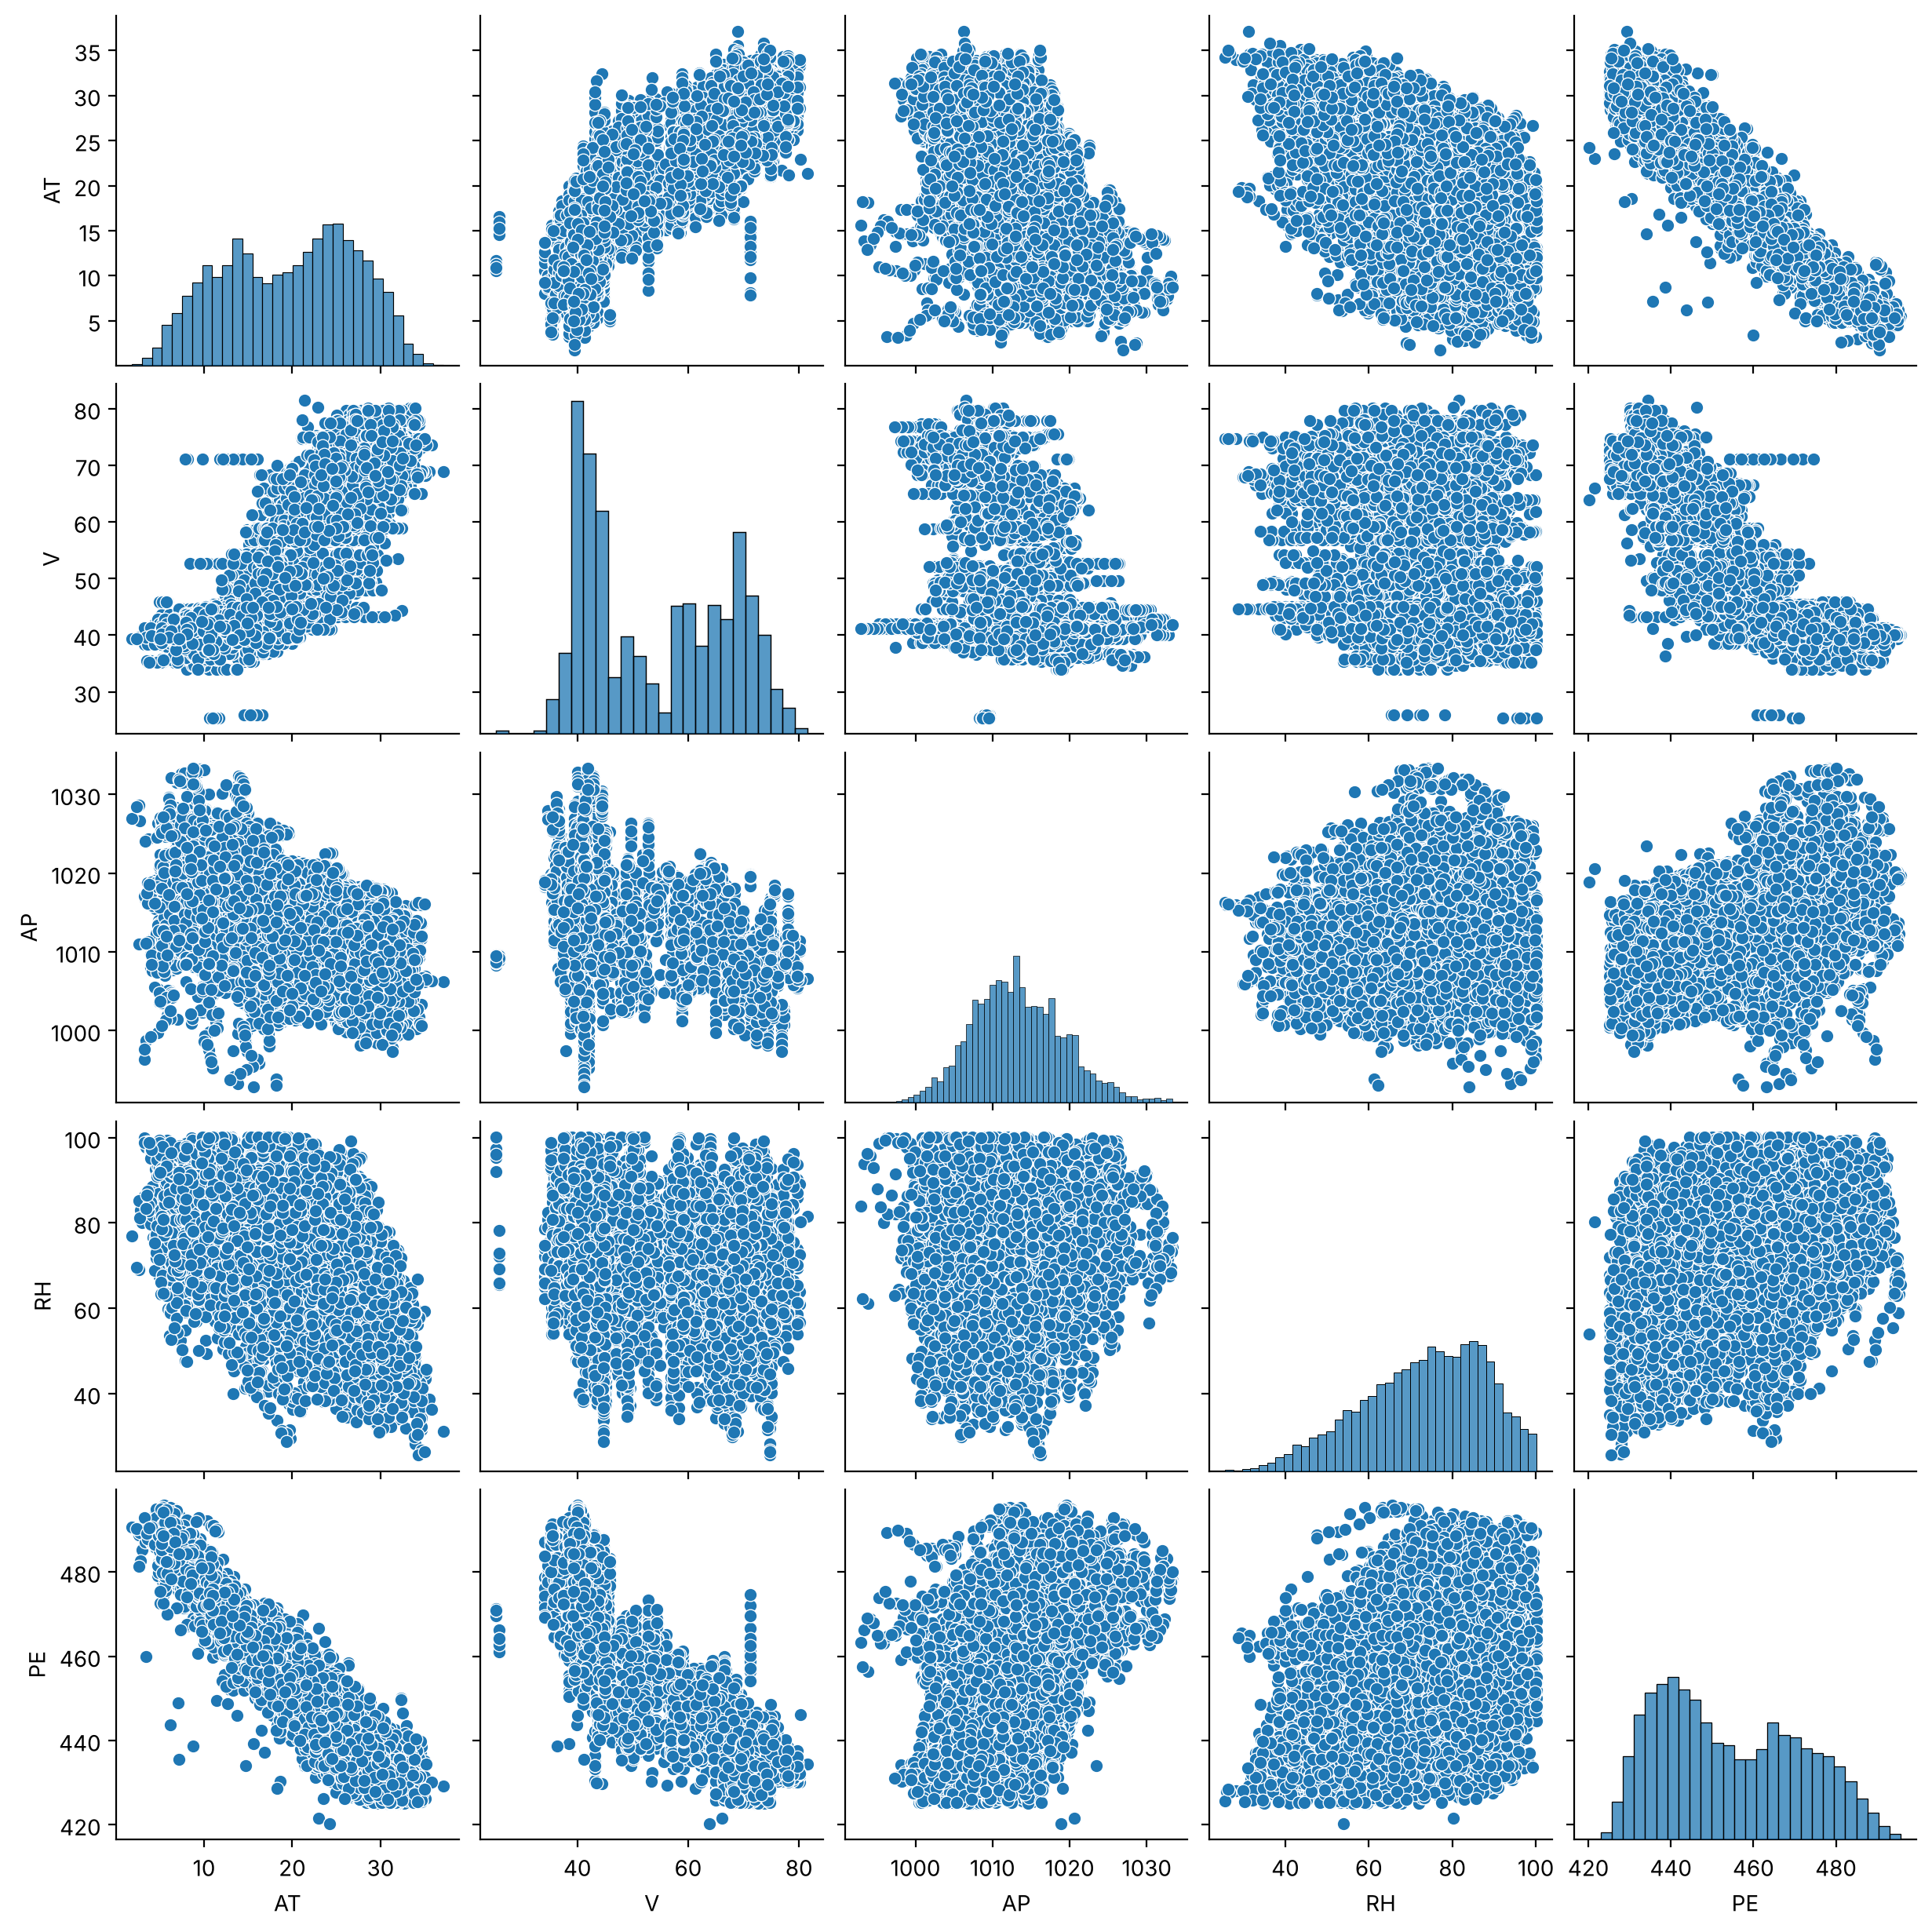

In [4]:
sns.pairplot(df)
plt.show()

**Pairwise Scatterplots**

From the pairwise scatterplots, we observe the following:

- The dependent variable **PE** shows a **strong negative linear relationship** with
  **Ambient Temperature (AT)**, indicating that higher temperatures reduce power output.
- **Exhaust Vacuum (V)** also exhibits a noticeable negative relationship with **PE**.
- **Ambient Pressure (AP)** shows a **positive relationship** with **PE**, though weaker
  compared to AT and V.
- **Relative Humidity (RH)** has a relatively **weak relationship** with PE.
- The relationships between predictors themselves appear mostly linear, with no strong
  evidence of severe nonlinearity or clustering.

Overall, the plots suggest that linear regression models are reasonable, though some
nonlinear effects may exist, particularly for temperature.

#### Summary statistics


In [5]:
summary_stats = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Min': df.min(),
    'Max': df.max(),
    'Range': df.max() - df.min(),
    'Q1': df.quantile(0.25),
    'Q3': df.quantile(0.75)
})

summary_stats['IQR'] = summary_stats['Q3'] - summary_stats['Q1']

summary_stats = summary_stats[
    ['Mean', 'Median', 'Range', 'Q1', 'Q3', 'IQR', 'Min', 'Max']
]

summary_stats

,Mean,Median,Range,Q1,Q3,IQR,Min,Max
AT,19.651231,20.345,35.30,13.5100,25.72,12.2100,1.81,37.11
V,54.305804,52.080,56.20,41.7400,66.54,24.8000,25.36,81.56
AP,1013.259078,1012.940,40.41,1009.1000,1017.26,8.1600,992.89,1033.30
RH,73.308978,74.975,74.60,63.3275,84.83,21.5025,25.56,100.16
PE,454.365009,451.550,75.50,439.7500,468.43,28.6800,420.26,495.76


## 2. One predictor at a time


In [6]:
predictors = ['AT', 'V', 'AP', 'RH']
models = {}
results = []

for col in predictors:
    formula = f"PE ~ {col}"
    model = smf.ols(formula=formula, data=df).fit()
    models[col] = model

    # Safe param extraction
    intercept = model.params.get('Intercept', model.params.iloc[0])
    slope = model.params.get(col, np.nan)
    pval = model.pvalues.get(col, np.nan)
    r2 = model.rsquared

    # Influence / outliers
    infl = model.get_influence()
    student_resid = infl.resid_studentized_internal
    student_resid_series = pd.Series(student_resid, index=df.index)
    outlier_mask = student_resid_series.abs() > 3
    n_outliers = int(outlier_mask.sum())

    # Cook's distance (top 3 indices)
    cooks_d = infl.cooks_distance[0]
    cooks_series = pd.Series(cooks_d, index=df.index)
    top_cook_idx = cooks_series.nlargest(3).index.tolist()

    results.append({
        'predictor': col,
        'slope': slope,
        'intercept': intercept,
        'p_value': pval,
        'R2': r2,
        'n_outliers': n_outliers,
        'top_cook_idx': top_cook_idx
    })

# I am also including a summary table for the notebook
summary_univariate = pd.DataFrame(results).set_index('predictor')
summary_univariate[['slope','intercept','p_value','R2','n_outliers','top_cook_idx']]

,slope,intercept,p_value,R2,n_outliers,top_cook_idx
predictor,,,,,,
AT,-2.171320,497.034120,0.0,0.898948,42,"[7664, 3383, 8362]"
V,-1.168135,517.801526,0.0,0.756518,33,"[3103, 2993, 3117]"
AP,1.489872,-1055.260989,0.0,0.268769,29,"[1290, 7182, 7077]"
RH,0.455650,420.961766,0.0,0.151939,2,"[3603, 8751, 5188]"


The table above lists slope, intercept, p-value, R², number of flagged studentized-residual outliers (|t|>3), and top Cook's-distance indices for each univariate OLS model.

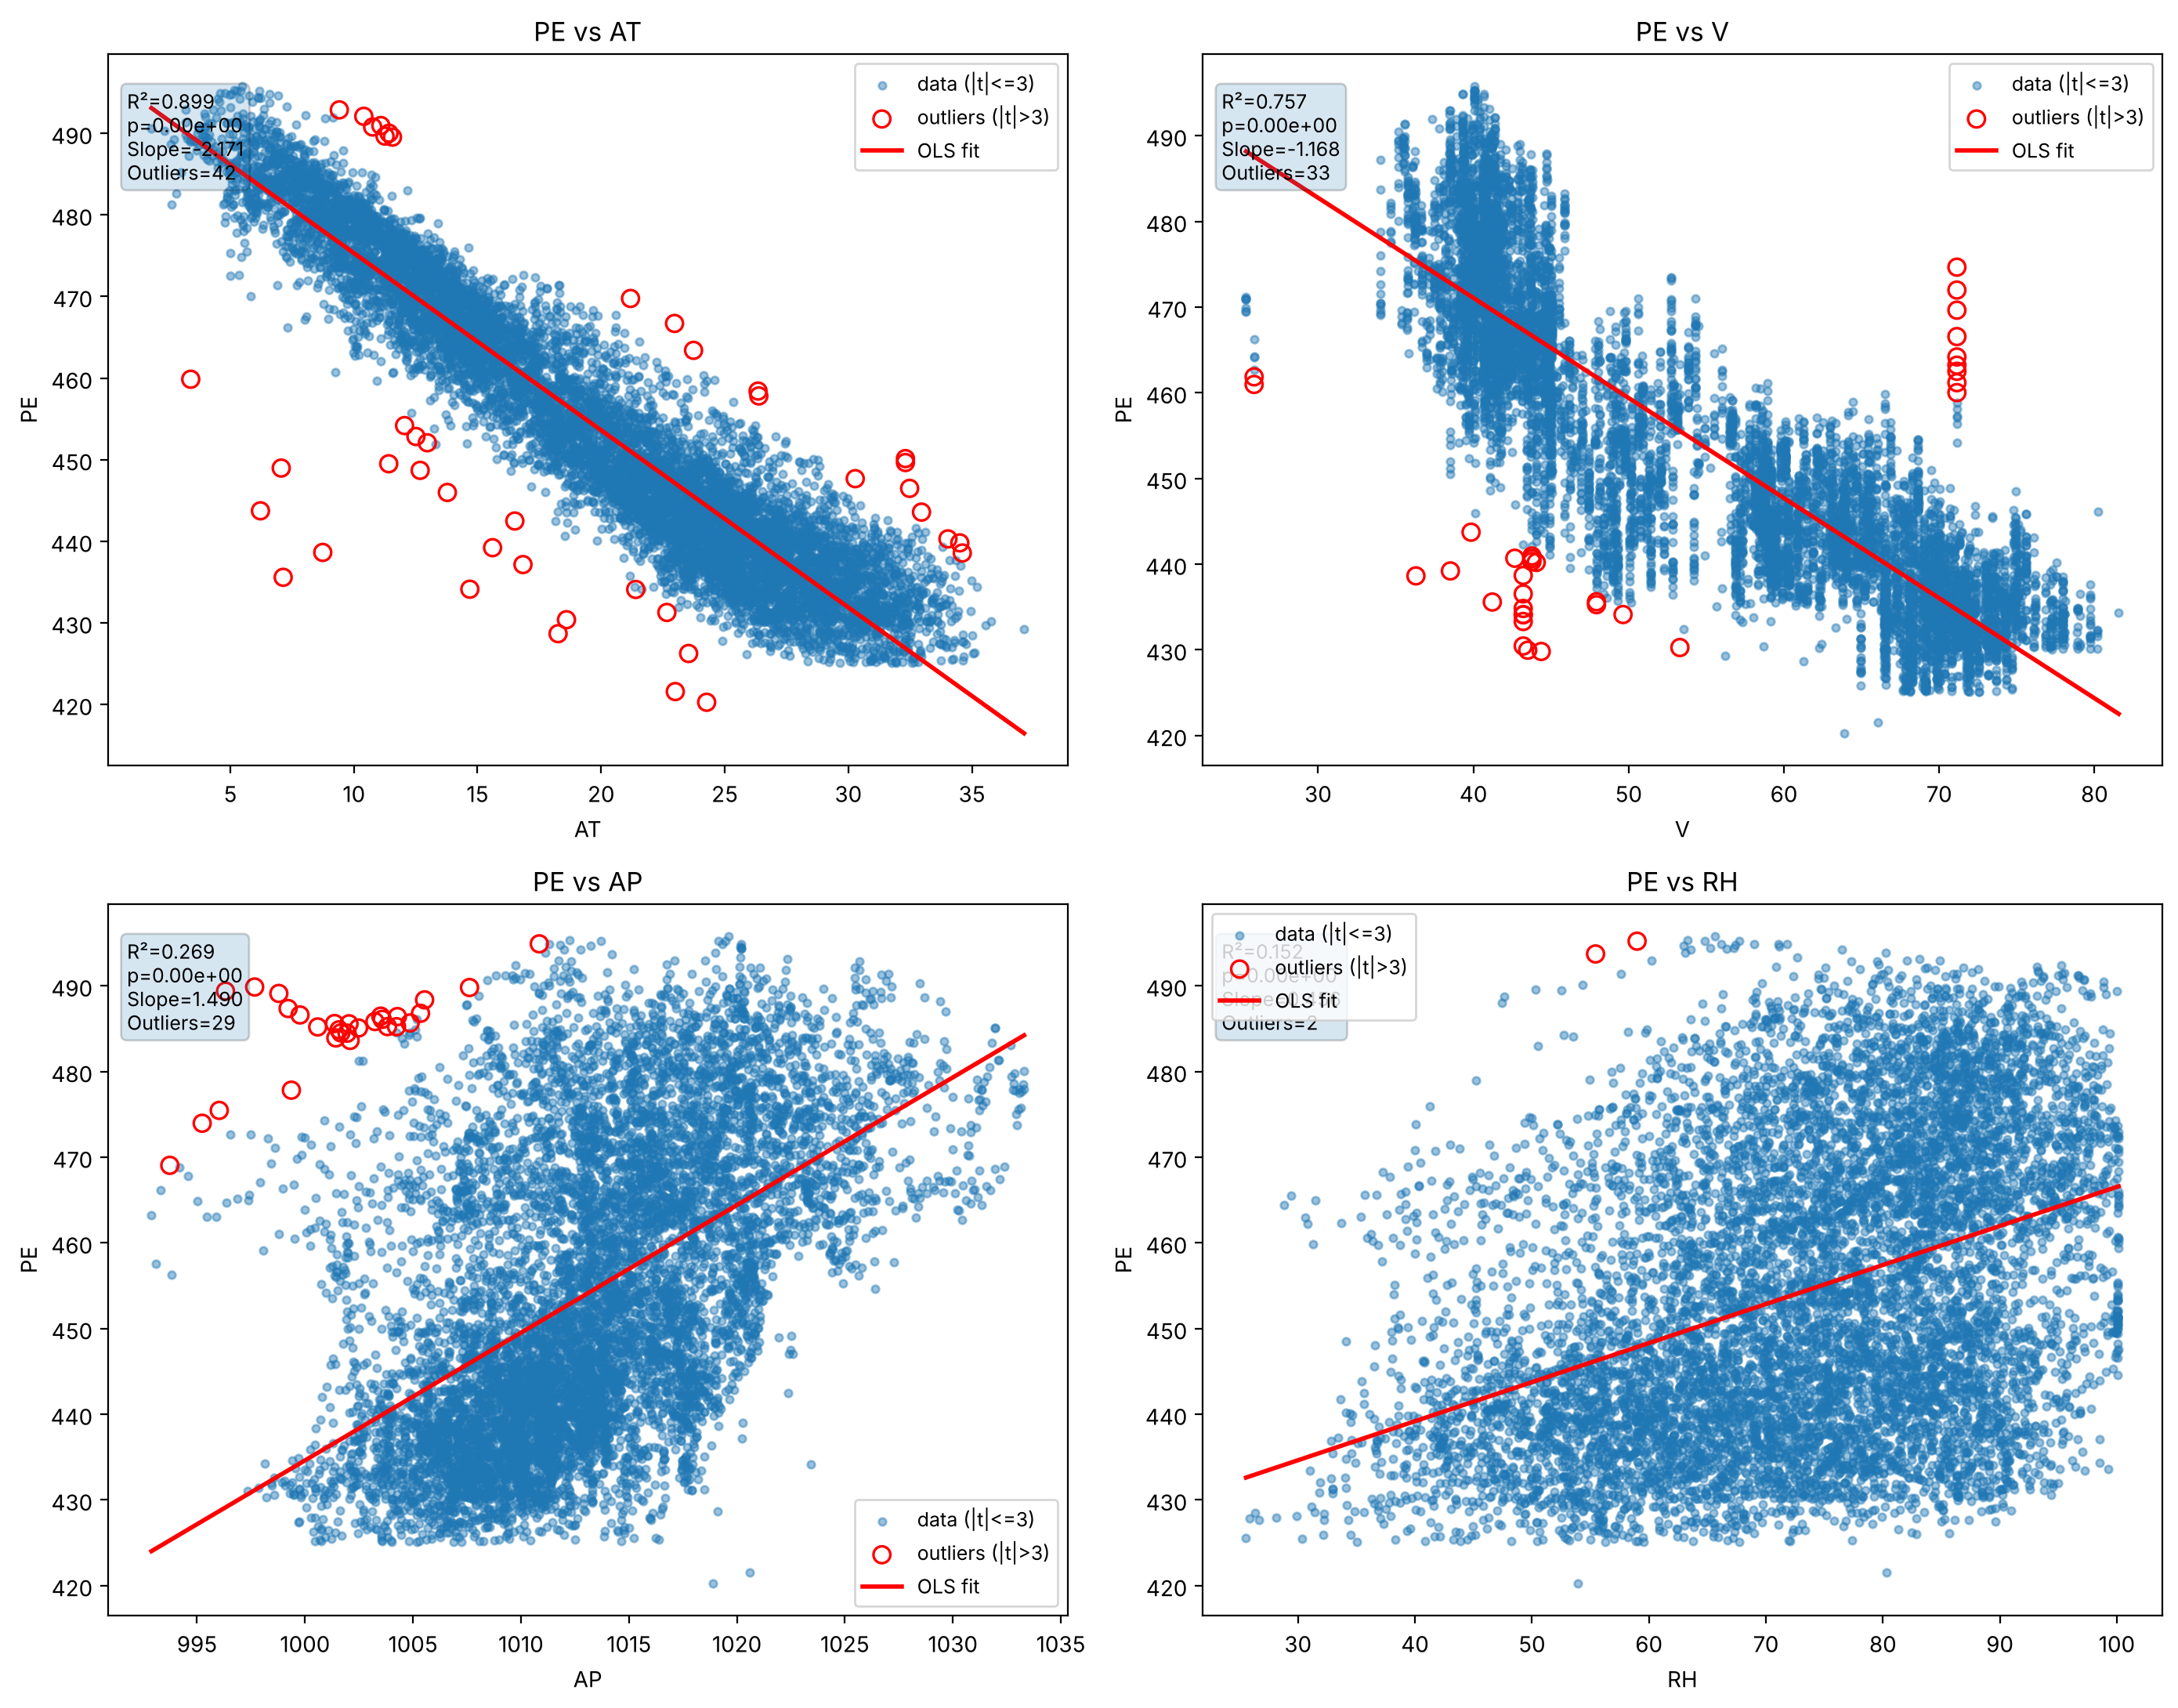

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for i, col in enumerate(predictors):
    ax = axes[i]
    model = models[col]

    x = df[col]
    y = df['PE']
    infl = model.get_influence()
    student_resid = infl.resid_studentized_internal
    student_resid_series = pd.Series(student_resid, index=df.index)
    outlier_mask = student_resid_series.abs() > 3

    # Plot non-outliers and outliers
    ax.scatter(x[~outlier_mask], y[~outlier_mask], s=12, alpha=0.45, label='data (|t|<=3)')
    if outlier_mask.sum() > 0:
        ax.scatter(x[outlier_mask], y[outlier_mask], facecolors='none', edgecolors='r',
                   s=60, linewidths=1.2, label='outliers (|t|>3)')

    # Fitted line (predict on grid)
    x_grid = np.linspace(x.min(), x.max(), 300)
    X_pred = pd.DataFrame({col: x_grid})
    y_pred = model.predict(X_pred)
    ax.plot(x_grid, y_pred, color='red', linewidth=2, label='OLS fit')

    s = summary_univariate.loc[col]
    stats_text = f"R²={s['R2']:.3f}\np={s['p_value']:.2e}\nSlope={s['slope']:.3f}\nOutliers={int(s['n_outliers'])}"
    ax.text(0.02, 0.95, stats_text, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', bbox=dict(boxstyle='round', alpha=0.18))

    ax.set_xlabel(col)
    ax.set_ylabel('PE')
    ax.set_title(f"PE vs {col}")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

The plots show `PE` against each predictor with the OLS fit (red), and points with studentized residuals beyond ±3 circled.

**Should outliers be removed?** The next cell refits each model without them. Slopes move by less than 1% (AT: −2.171 → −2.180) and R² rises by at most 0.017. The flagged hours aren't errors either: they're valid readings in the tails, so they stay in.


In [8]:

refit_results = []

for col in predictors:
    model_orig = models[col]
    infl = model_orig.get_influence()
    student_resid = infl.resid_studentized_internal
    student_resid_series = pd.Series(student_resid, index=df.index)
    outlier_mask = student_resid_series.abs() > 3

    # create df_no_out = df without those outliers
    df_no_out = df.loc[~outlier_mask].copy()

    # re-fit
    model_no_out = smf.ols(formula=f"PE ~ {col}", data=df_no_out).fit()

    # capture before/after
    before = {
        'slope_before': model_orig.params.get(col, np.nan),
        'R2_before': model_orig.rsquared
    }
    after = {
        'slope_after': model_no_out.params.get(col, np.nan),
        'R2_after': model_no_out.rsquared,
        'n_removed': int(outlier_mask.sum())
    }

    # append
    refit_results.append({
        'predictor': col,
        **before,
        **after
    })

refit_summary = pd.DataFrame(refit_results).set_index('predictor')
refit_summary

,slope_before,R2_before,slope_after,R2_after,n_removed
predictor,,,,,
AT,-2.171320,0.898948,-2.180227,0.906378,42
V,-1.168135,0.756518,-1.176889,0.766990,33
AP,1.489872,0.268769,1.538973,0.285978,29
RH,0.455650,0.151939,0.456399,0.152576,2


Removing the flagged points barely changes any coefficient, which confirms they aren't distorting the fits. All later models use the full dataset.


## 3. Multiple regression


In [9]:
formula = 'PE ~ AT + V + AP + RH'
mlr_model = smf.ols(formula=formula, data=df).fit()

mlr_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:09:01   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    454.6093      9.749     46.634      0.000     435.500     473.718
AT            -1.9775      0.015   -129.342      0.000      -2.007      -1.948
V             -0.2339      0.007    -32.122      0.000      -0.248      -0.220
AP             0.0621      0.009      6.564      0.000       0.044       0.081
RH            -0.1581      0.004    -37.918      0.000      -0.166      -0.150
==============================================================================
Omnibus:                      892.002   Durbin-Watson:                   2.033
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4086.777
Skew:                          -0.352   Prob(JB):                         0.00
Kurtosis:                       6.123   Cond. No.                     2.13e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.13e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

**Results**

The multiple linear regression model explains a substantial portion of the
variation in the net electrical energy output.

The R-squared value is approximately 0.93, indicating that the four predictors
(AT, V, AP, and RH) together account for about 93% of the variability in PE.
The very small Prob(F-statistic) value shows that the model as a whole is
statistically significant.

**Individual Predictors**

- **Ambient Temperature (AT)** has a negative coefficient, indicating that higher
  temperatures are associated with lower power output.
- **Exhaust Vacuum (V)** also shows a negative relationship with PE.
- **Ambient Pressure (AP)** has a positive coefficient, suggesting higher pressure
  slightly increases power output.
- **Relative Humidity (RH)** has a negative coefficient, though its effect size is
  smaller compared to AT and V.

**Hypothesis Testing**

For each predictor, we test the null hypothesis H₀: βⱼ = 0.
Using a significance level of 0.05, all predictors have p-values well below
this threshold (p < 0.001). Therefore, we reject the null hypothesis for all
four variables and conclude that each predictor contributes significantly
to predicting PE in the multiple regression model.

### Simple vs. multiple regression coefficients


In [10]:
import statsmodels.formula.api as smf
import pandas as pd

predictors = ['AT', 'V', 'AP', 'RH']

# coefficients from one-predictor regressions
slr_coefs = {}

for col in predictors:
    model = smf.ols(f"PE ~ {col}", data=df).fit()
    slr_coefs[col] = model.params[col]

# coefficients from the multiple regression
mlr_coefs = mlr_model.params[predictors]

# combine into a single DataFrame
coef_df = pd.DataFrame({
    'Simple_Regression': slr_coefs,
    'Multiple_Regression': mlr_coefs
})

coef_df

,Simple_Regression,Multiple_Regression
AT,-2.171320,-1.977513
V,-1.168135,-0.233916
AP,1.489872,0.062083
RH,0.455650,-0.158054


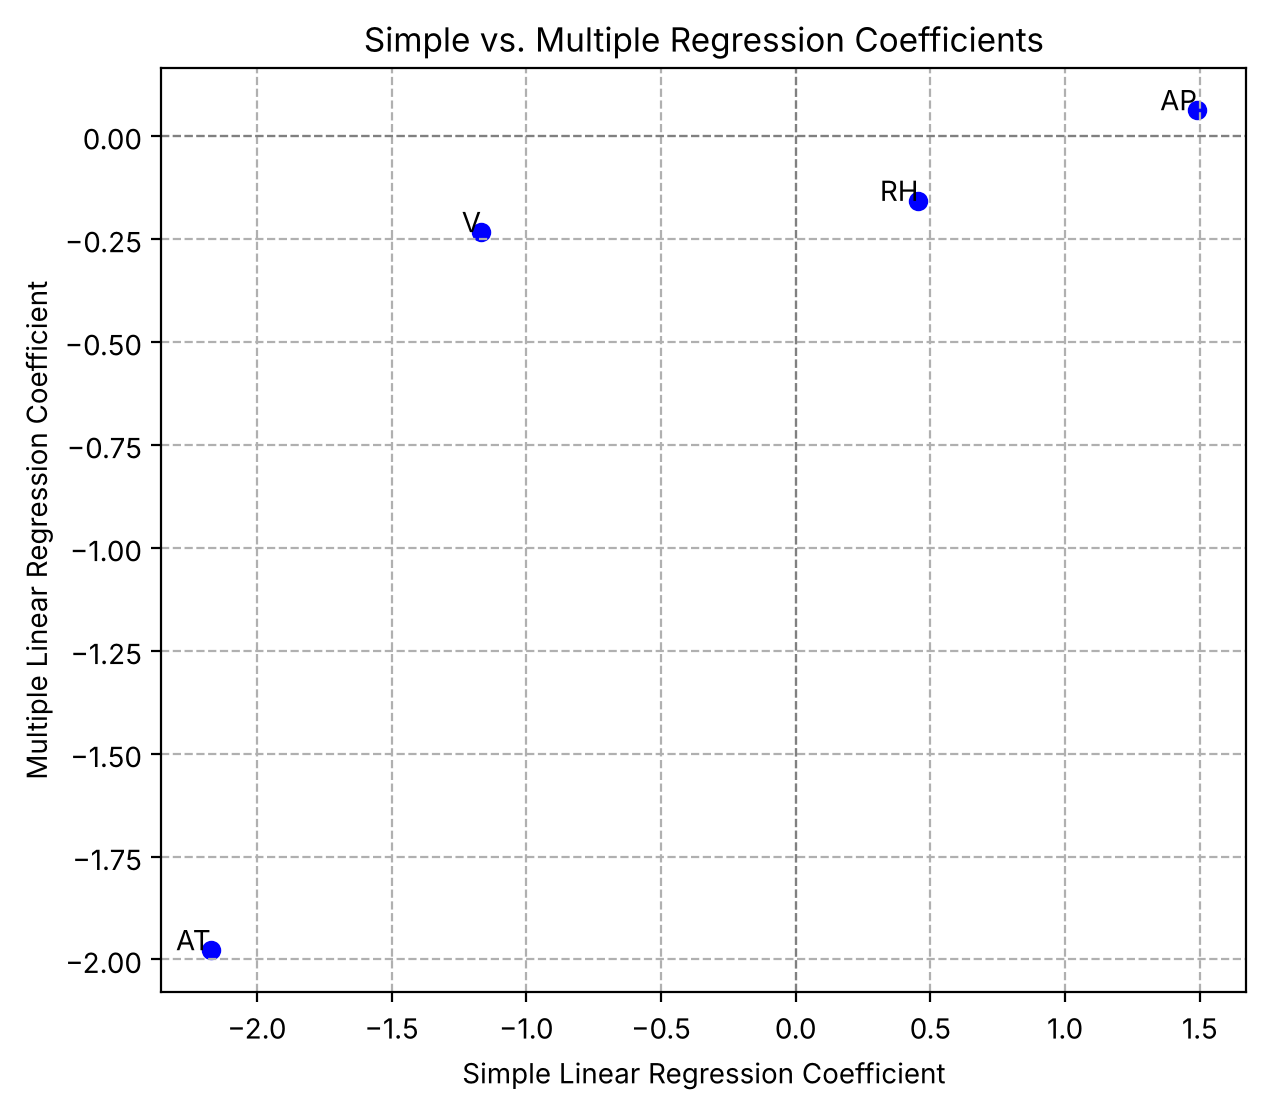

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    coef_df['Simple_Regression'],
    coef_df['Multiple_Regression'],
    color='blue'
)

# label each point with predictor name
for predictor in coef_df.index:
    plt.text(
        coef_df.loc[predictor, 'Simple_Regression'],
        coef_df.loc[predictor, 'Multiple_Regression'],
        predictor,
        fontsize=10,
        ha='right'
    )
plt.grid(alpha=1.0, linestyle='--')

plt.xlabel('Simple Linear Regression Coefficient')
plt.ylabel('Multiple Linear Regression Coefficient')
plt.title('Simple vs. Multiple Regression Coefficients')

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)

plt.show()

**Comparison.** Three coefficients keep their sign but shrink sharply once the other predictors are held fixed. V drops from −1.17 to −0.23 and AP from 1.49 to 0.06, because most of what they "explained" alone was really temperature (AT is correlated with V at 0.84 and with AP at −0.51).

**Relative humidity flips sign**, from +0.46 alone to −0.16 in the multiple regression. Humid hours tend to be cooler hours (corr(AT, RH) = −0.54), and cool air raises output, so RH looks helpful on its own. Holding temperature fixed, more humidity slightly *lowers* output. That's a textbook case of confounding.


## 4. Nonlinear association


In [13]:
predictors = ['AT', 'V', 'AP', 'RH']
nonlinear_results = []

print("Cubic Polynomial Regression Results:\n")

for col in predictors:
    formula = f'PE ~ {col} + I({col}**2) + I({col}**3)'
    model = smf.ols(formula=formula, data=df).fit()

    r2 = model.rsquared
    p_lin = model.pvalues[col]
    p_quad = model.pvalues[f'I({col} ** 2)']
    p_cubic = model.pvalues[f'I({col} ** 3)']

    nonlinear = (p_quad < 0.05) or (p_cubic < 0.05)

    print(f"{col}:")
    print(f"  R² = {r2:.4f}")
    print(f"  p-value for {col}   = {p_lin:.2e}")
    print(f"  p-value for {col}²  = {p_quad:.2e}")
    print(f"  p-value for {col}³  = {p_cubic:.2e}")
    print(f"  Evidence of nonlinearity? {'YES' if nonlinear else 'NO'}\n")

    nonlinear_results.append({
        'Predictor': col,
        'R2': r2,
        'p_linear': p_lin,
        'p_quadratic': p_quad,
        'p_cubic': p_cubic,
        'Nonlinear_Evidence': nonlinear
    })

nonlinear_summary = pd.DataFrame(nonlinear_results).set_index('Predictor')
nonlinear_summary

Cubic Polynomial Regression Results:

AT:
  R² = 0.9119
  p-value for AT   = 7.90e-07
  p-value for AT²  = 8.83e-73
  p-value for AT³  = 3.65e-110
  Evidence of nonlinearity? YES

V:
  R² = 0.7750
  p-value for V   = 2.53e-05
  p-value for V²  = 7.68e-01
  p-value for V³  = 1.37e-02
  Evidence of nonlinearity? YES

AP:
  R² = 0.2749
  p-value for AP   = 4.50e-17
  p-value for AP²  = 3.67e-17
  p-value for AP³  = 8.26e-18
  Evidence of nonlinearity? YES

RH:
  R² = 0.1537
  p-value for RH   = 3.77e-04
  p-value for RH²  = 9.40e-06
  p-value for RH³  = 1.44e-05
  Evidence of nonlinearity? YES



,R2,p_linear,p_quadratic,p_cubic,Nonlinear_Evidence
Predictor,,,,,
AT,0.911883,7.898147e-07,8.833045e-73,3.652185e-110,True
V,0.775022,2.526589e-05,7.684969e-01,1.373489e-02,True
AP,0.274863,4.502735e-17,3.666705e-17,8.264146e-18,True
RH,0.153743,3.772510e-04,9.395430e-06,1.440279e-05,True


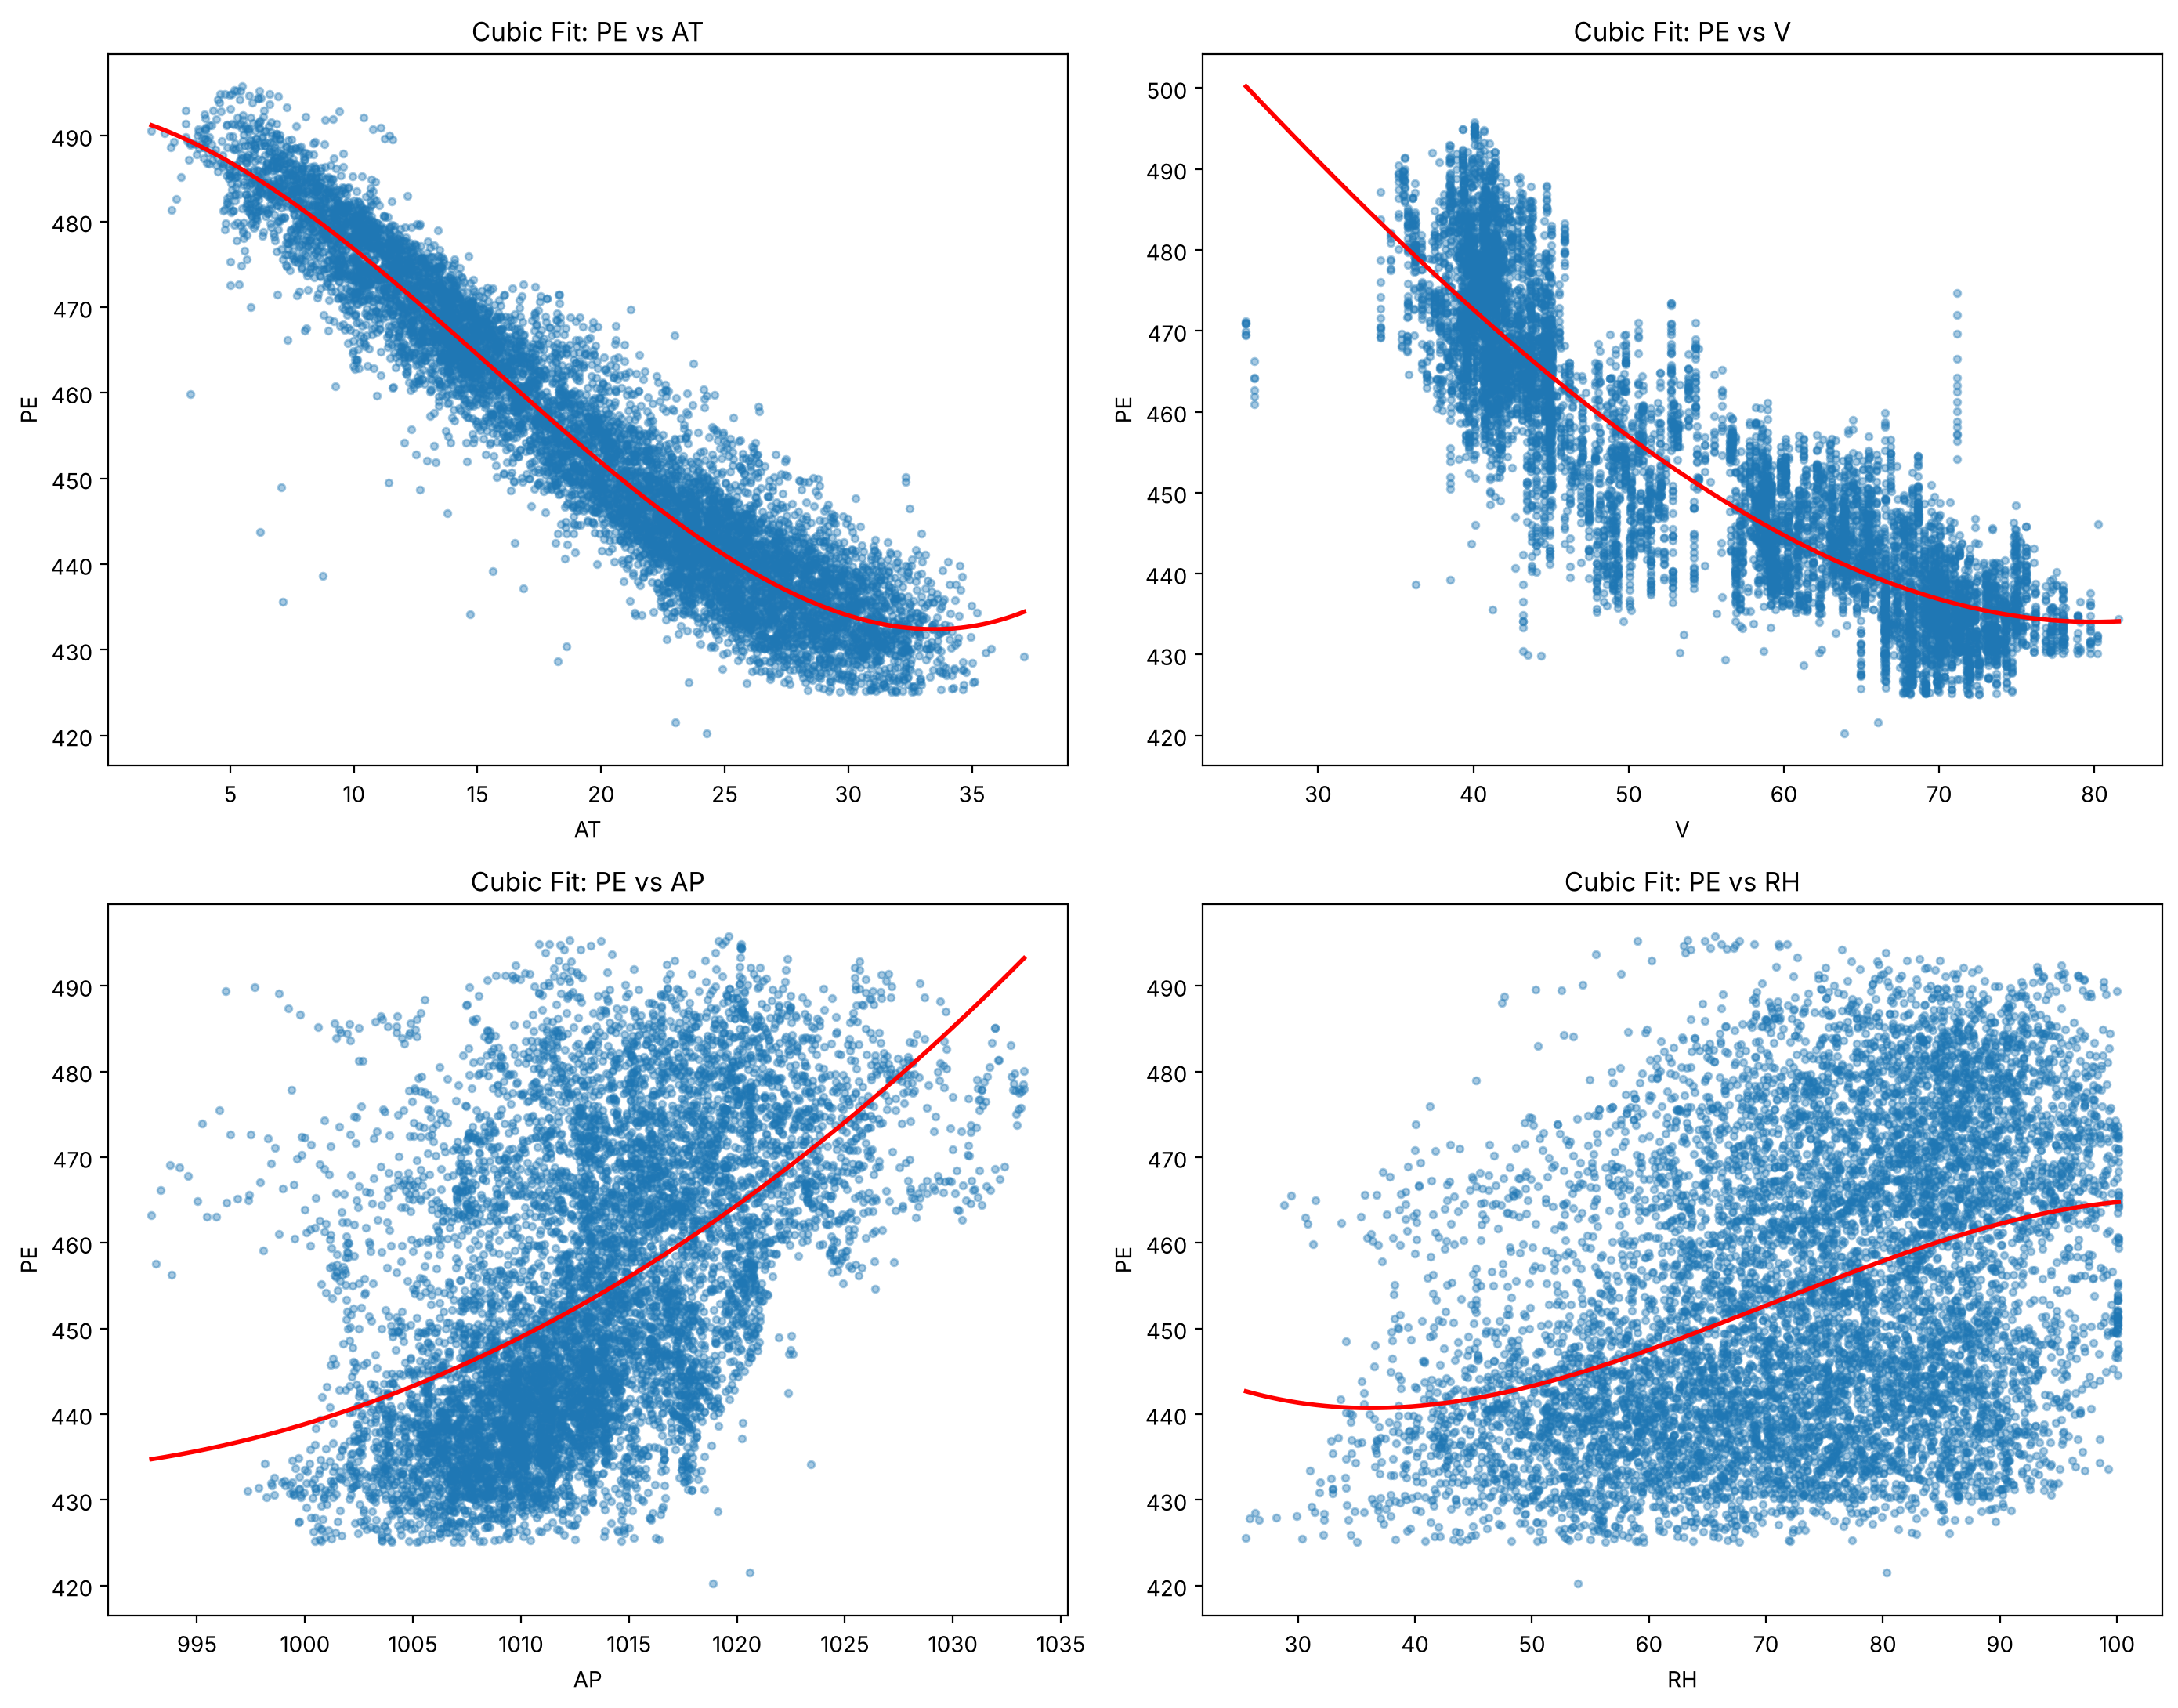

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for i, col in enumerate(predictors):
    ax = axes[i]

    # Fit cubic model
    model = smf.ols(f'PE ~ {col} + I({col}**2) + I({col}**3)', data=df).fit()

    # Scatter
    ax.scatter(df[col], df['PE'], s=10, alpha=0.4)

    # Smooth curve
    x_grid = np.linspace(df[col].min(), df[col].max(), 300)
    X_pred = pd.DataFrame({col: x_grid})
    y_pred = model.predict(X_pred)

    ax.plot(x_grid, y_pred, color='red', linewidth=2)

    ax.set_xlabel(col)
    ax.set_ylabel('PE')
    ax.set_title(f'Cubic Fit: PE vs {col}')

plt.tight_layout()
plt.show()

For each predictor we fit PE = β₀ + β₁X + β₂X² + β₃X³ + ε and look at the p-values of the higher-order terms.

- **AT** shows the clearest nonlinearity (p ≈ 10⁻¹¹⁰ for the cubic term), and R² rises from 0.899 to 0.912. The cubic curve visibly bends at both ends.
- **AP and RH** have significant higher-order terms, but R² barely moves (+0.006 and +0.002). With 9,568 points even tiny curvature becomes "significant".
- **V**'s quadratic term is not significant (p = 0.77) and its cubic term only weakly so (p = 0.014).

Statistical significance and practical importance aren't the same thing here: only temperature's curvature is worth modelling.


## 5. Interactions between predictors


In [15]:
formula = 'PE ~ (AT + V + AP + RH)**2'
interaction_model = smf.ols(formula=formula, data=df).fit()

interaction_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:09:02   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.000     531.631     839.934
AT            -4.3470      2.373     -1.832      0.067      -8.999       0.305
V             -7.6749      1.351     -5.682      0.000     -10.323      -5.027
AP            -0.1524      0.077     -1.983      0.047      -0.303      -0.002
RH             1.5709      0.773      2.031      0.042       0.055       3.087
AT:V           0.0210      0.001     23.338      0.000       0.019       0.023
AT:AP          0.0018      0.002      0.752      0.452      -0.003       0.006
AT:RH         -0.0052      0.001     -6.444      0.000      -0.007      -0.004
V:AP           0.0068      0.001      5.135      0.000       0.004       0.009
V:RH           0.0008      0.000      1.716      0.086      -0.000       0.002
AP:RH         -0.0016      0.001     -2.125      0.034      -0.003      -0.000
==============================================================================
Omnibus:                     1454.609   Durbin-Watson:                   2.030
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9170.848
Skew:                          -0.574   Prob(JB):                         0.00
Kurtosis:                       7.657   Cond. No.                     1.70e+08
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.7e+08. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [16]:
interaction_pvalues = interaction_model.pvalues[
    interaction_model.pvalues.index.str.contains(':')
]

# Filter statistically significant interactions
significant_interactions = interaction_pvalues[interaction_pvalues < 0.05]

print(f"Total interaction terms tested: {len(interaction_pvalues)}")
print(f"Statistically significant interactions (p < 0.05): {len(significant_interactions)}\n")

significant_interactions.sort_values()

Total interaction terms tested: 6
Statistically significant interactions (p < 0.05): 4



AT:V     3.333358e-117
AT:RH     1.216944e-10
V:AP      2.877026e-07
AP:RH     3.360557e-02
dtype: float64

**Interactions.** Four of the six pairwise interactions are significant at 0.05. **AT:V** dominates (p ≈ 10⁻¹¹⁷), followed by AT:RH (10⁻¹⁰), V:AP (10⁻⁷) and, marginally, AP:RH (0.03). R² rises from 0.929 to 0.936.

The effect of temperature on output depends on exhaust vacuum. That makes physical sense: both describe how efficiently the turbines can reject heat.


## 6. Building a better linear model


In [17]:
RANDOM_STATE = 42
train_df, test_df = train_test_split(df, train_size=0.7, random_state=RANDOM_STATE)

print("Train shape:", train_df.shape)
print("Test  shape:", test_df.shape)

Train shape: (6697, 5)
Test  shape: (2871, 5)


In [18]:
# Baseline model 
baseline_formula = 'PE ~ AT + V + AP + RH'
baseline_model = smf.ols(baseline_formula, data=train_df).fit()

# predictions
train_pred_base = baseline_model.predict(train_df)
test_pred_base  = baseline_model.predict(test_df)

# MSEs
train_mse_base = mean_squared_error(train_df['PE'], train_pred_base)
test_mse_base  = mean_squared_error(test_df['PE'], test_pred_base)

print("Baseline model (main effects only)")
print(f" Train MSE: {train_mse_base:.4f}")
print(f" Test  MSE: {test_mse_base:.4f}")

Baseline model (main effects only)
 Train MSE: 20.5808
 Test  MSE: 21.2399


In [19]:

full_formula = (
    'PE ~ (AT + V + AP + RH)**2 '
    '+ I(AT ** 2) + I(V ** 2) + I(AP ** 2) + I(RH ** 2)'
)

full_model = smf.ols(full_formula, data=train_df).fit()
print("Full enhanced model fitted on training data. Top summary:")
display(full_model.summary().tables[0])

terms = list(full_model.params.index)
print("\nTerms in the full model:")
print(terms)

Full enhanced model fitted on training data. Top summary:


Dep. Variable:,PE,R-squared:,0.938
Model:,OLS,Adj. R-squared:,0.938
Method:,Least Squares,F-statistic:,7272.
Date:,"Thu, 26 Nov 2026",Prob (F-statistic):,0.00
Time:,18:09:02,Log-Likelihood:,-19160.
No. Observations:,6697,AIC:,3.835e+04
Df Residuals:,6682,BIC:,3.845e+04
Df Model:,14,,
Covariance Type:,nonrobust,,



Terms in the full model:
['Intercept', 'AT', 'V', 'AP', 'RH', 'AT:V', 'AT:AP', 'AT:RH', 'V:AP', 'V:RH', 'AP:RH', 'I(AT ** 2)', 'I(V ** 2)', 'I(AP ** 2)', 'I(RH ** 2)']


In [20]:
alpha = 0.05

current_terms = [t for t in full_model.pvalues.index if t != 'Intercept']

def is_main_effect(term):
    return term in ['AT', 'V', 'AP', 'RH']

def term_contains_main(term, main):
    # Interaction: 'AT:V' -> split(':')
    if ':' in term:
        return main in term.split(':')
    # Polynomial: "I(AT ** 2)" or "I(AT ** 3)" -> check within parentheses
    if term.startswith('I('):
        return f"{main}" in term
    # else not containing main
    return False

removal_log = []
loop_count = 0

while True:
    loop_count += 1
    # Fit model with current terms
    formula_rhs = ' + '.join(current_terms) if current_terms else '1'
    formula = 'PE ~ ' + formula_rhs
    model = smf.ols(formula, data=train_df).fit()
    pvals = model.pvalues.drop('Intercept', errors='ignore')
    if pvals.empty:
        break

    # candidate: the term with the largest p-value
    max_term = pvals.idxmax()
    max_p = pvals.max()

    # stop if all p-values <= alpha
    if max_p <= alpha:
        break

    # determine removability
    removable = True
    if is_main_effect(max_term):
        # don't remove main effect if any remaining term depends on it
        for other in current_terms:
            if other == max_term:
                continue
            if term_contains_main(other, max_term):
                removable = False
                break

    if removable:
        current_terms.remove(max_term)
        removal_log.append((max_term, max_p))
        print(f"Removed '{max_term}' (p = {max_p:.4f})")
        continue
    else:
        # try to find next-highest removable term
        sorted_p = pvals.sort_values(ascending=False)
        found = False
        for term_name, pval in sorted_p.items():
            if pval <= alpha:
                break  # nothing left to remove
            if is_main_effect(term_name):
                # check if any other term depends on this main term
                can_remove = True
                for other in current_terms:
                    if other == term_name:
                        continue
                    if term_contains_main(other, term_name):
                        can_remove = False
                        break
                if can_remove:
                    current_terms.remove(term_name)
                    removal_log.append((term_name, pval))
                    print(f"Removed '{term_name}' (p = {pval:.4f})")
                    found = True
                    break
            else:
                # interaction or polynomial can be removed
                current_terms.remove(term_name)
                removal_log.append((term_name, pval))
                print(f"Removed '{term_name}' (p = {pval:.4f})")
                found = True
                break
        if not found:
            print("No removable high-p term found without violating hierarchy. Stopping elimination.")
            break

print("\nBackward elimination finished.")
print("Removed terms (in order):")
for term, p in removal_log:
    print(f" - {term} (p = {p:.4f})")


if current_terms:
    reduced_formula = 'PE ~ ' + ' + '.join(current_terms)
else:
    reduced_formula = 'PE ~ 1'  # only intercept
print("\nFinal reduced formula:")
print(reduced_formula)

Removed 'V:RH' (p = 0.8674)
Removed 'I(V ** 2)' (p = 0.6077)
Removed 'V:AP' (p = 0.3578)

Backward elimination finished.
Removed terms (in order):
 - V:RH (p = 0.8674)
 - I(V ** 2) (p = 0.6077)
 - V:AP (p = 0.3578)

Final reduced formula:
PE ~ AT + V + AP + RH + AT:V + AT:AP + AT:RH + AP:RH + I(AT ** 2) + I(AP ** 2) + I(RH ** 2)


In [21]:
# Fit reduced enhanced model and compute MSEs 
reduced_model = smf.ols(reduced_formula, data=train_df).fit()

# predictions
train_pred_enh = reduced_model.predict(train_df)
test_pred_enh  = reduced_model.predict(test_df)

# MSEs
train_mse_enh = mean_squared_error(train_df['PE'], train_pred_enh)
test_mse_enh  = mean_squared_error(test_df['PE'], test_pred_enh)

print("Enhanced (reduced) model results:")
print(f" Train MSE: {train_mse_enh:.4f}")
print(f" Test  MSE: {test_mse_enh:.4f}")

Enhanced (reduced) model results:
 Train MSE: 17.8908
 Test  MSE: 18.6600


In [22]:
import pandas as pd

results_df = pd.DataFrame({
    'Model': ['Baseline (Main Effects)', 'Enhanced (Interactions+Quadratic, reduced)'],
    'Train MSE': [train_mse_base, train_mse_enh],
    'Test  MSE': [test_mse_base, test_mse_enh]
})

display(results_df.style.format({'Train MSE': '{:.4f}', 'Test  MSE': '{:.4f}'}))

print("\nConclusion:")
if test_mse_enh < test_mse_base:
    print(" - The enhanced reduced model achieves lower test MSE and thus generalizes better on the held-out data.")
else:
    print(" - The baseline model performs better (lower test MSE) or there is no improvement on test data.")

,Model,Train MSE,Test MSE
0,Baseline (Main Effects),20.5808,21.2399
1,"Enhanced (Interactions+Quadratic, reduced)",17.8908,18.6600



Conclusion:
 - The enhanced reduced model achieves lower test MSE and thus generalizes better on the held-out data.


**Summary.** Starting from all pairwise interactions plus squared terms (14 terms), backward elimination at α = 0.05, respecting hierarchy, removed V:RH, V², and V:AP.

| Model | Train MSE | Test MSE |
|---|---|---|
| Main effects only | 20.58 | 21.24 |
| Interactions + squares, reduced | 17.89 | **18.66** |

The richer linear model cuts test error by about 12% and the train/test gap stays small, so it isn't overfitting.


## 7. KNN regression


In [23]:
# Predictors and target
X = df[['AT', 'V', 'AP', 'RH']].copy()
y = df['PE'].copy()

# 70% train / 30% test 
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

# Normalizer (Min-Max scaling to [0,1]) fitted on training set
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler().fit(X_train)
X_train_norm = minmax.transform(X_train)
X_test_norm = minmax.transform(X_test)

# For reference: keep raw numpy arrays
X_train_raw = X_train.values
X_test_raw = X_test.values

print("Shapes:")
print(" X_train_raw:", X_train_raw.shape, " X_test_raw:", X_test_raw.shape)
print(" X_train_norm:", X_train_norm.shape, " X_test_norm:", X_test_norm.shape)

Shapes:
 X_train_raw: (6697, 4)  X_test_raw: (2871, 4)
 X_train_norm: (6697, 4)  X_test_norm: (2871, 4)


In [24]:
k_list = np.arange(1, 101)

train_mse_raw = []
test_mse_raw  = []

train_mse_norm = []
test_mse_norm  = []

for k in k_list:
    k = int(k)
    # raw features
    knn_raw = KNeighborsRegressor(n_neighbors=k)
    knn_raw.fit(X_train_raw, y_train)
    y_train_pred_raw = knn_raw.predict(X_train_raw)
    y_test_pred_raw  = knn_raw.predict(X_test_raw)
    train_mse_raw.append(mean_squared_error(y_train, y_train_pred_raw))
    test_mse_raw.append(mean_squared_error(y_test,  y_test_pred_raw))

    # normalized features (MinMax)
    knn_norm = KNeighborsRegressor(n_neighbors=k)
    knn_norm.fit(X_train_norm, y_train)
    y_train_pred_norm = knn_norm.predict(X_train_norm)
    y_test_pred_norm  = knn_norm.predict(X_test_norm)
    train_mse_norm.append(mean_squared_error(y_train, y_train_pred_norm))
    test_mse_norm.append(mean_squared_error(y_test,  y_test_pred_norm))

# pack results into DataFrame
results_knn = pd.DataFrame({
    'k': k_list,
    'train_mse_raw': train_mse_raw,
    'test_mse_raw':  test_mse_raw,
    'train_mse_norm': train_mse_norm,
    'test_mse_norm':  test_mse_norm
})
results_knn.head()

,k,train_mse_raw,test_mse_raw,train_mse_norm,test_mse_norm
0,1,0.000000,20.332543,0.000000,18.298757
1,2,5.500468,17.344087,5.204069,15.700308
2,3,8.126551,16.338840,7.168283,14.605432
3,4,9.444740,15.810755,8.454348,14.291333
4,5,10.600769,15.726820,9.602599,14.446174


Best k (raw features):        5  -> Test MSE = 15.7268
Best k (normalized features): 4  -> Test MSE = 14.2913


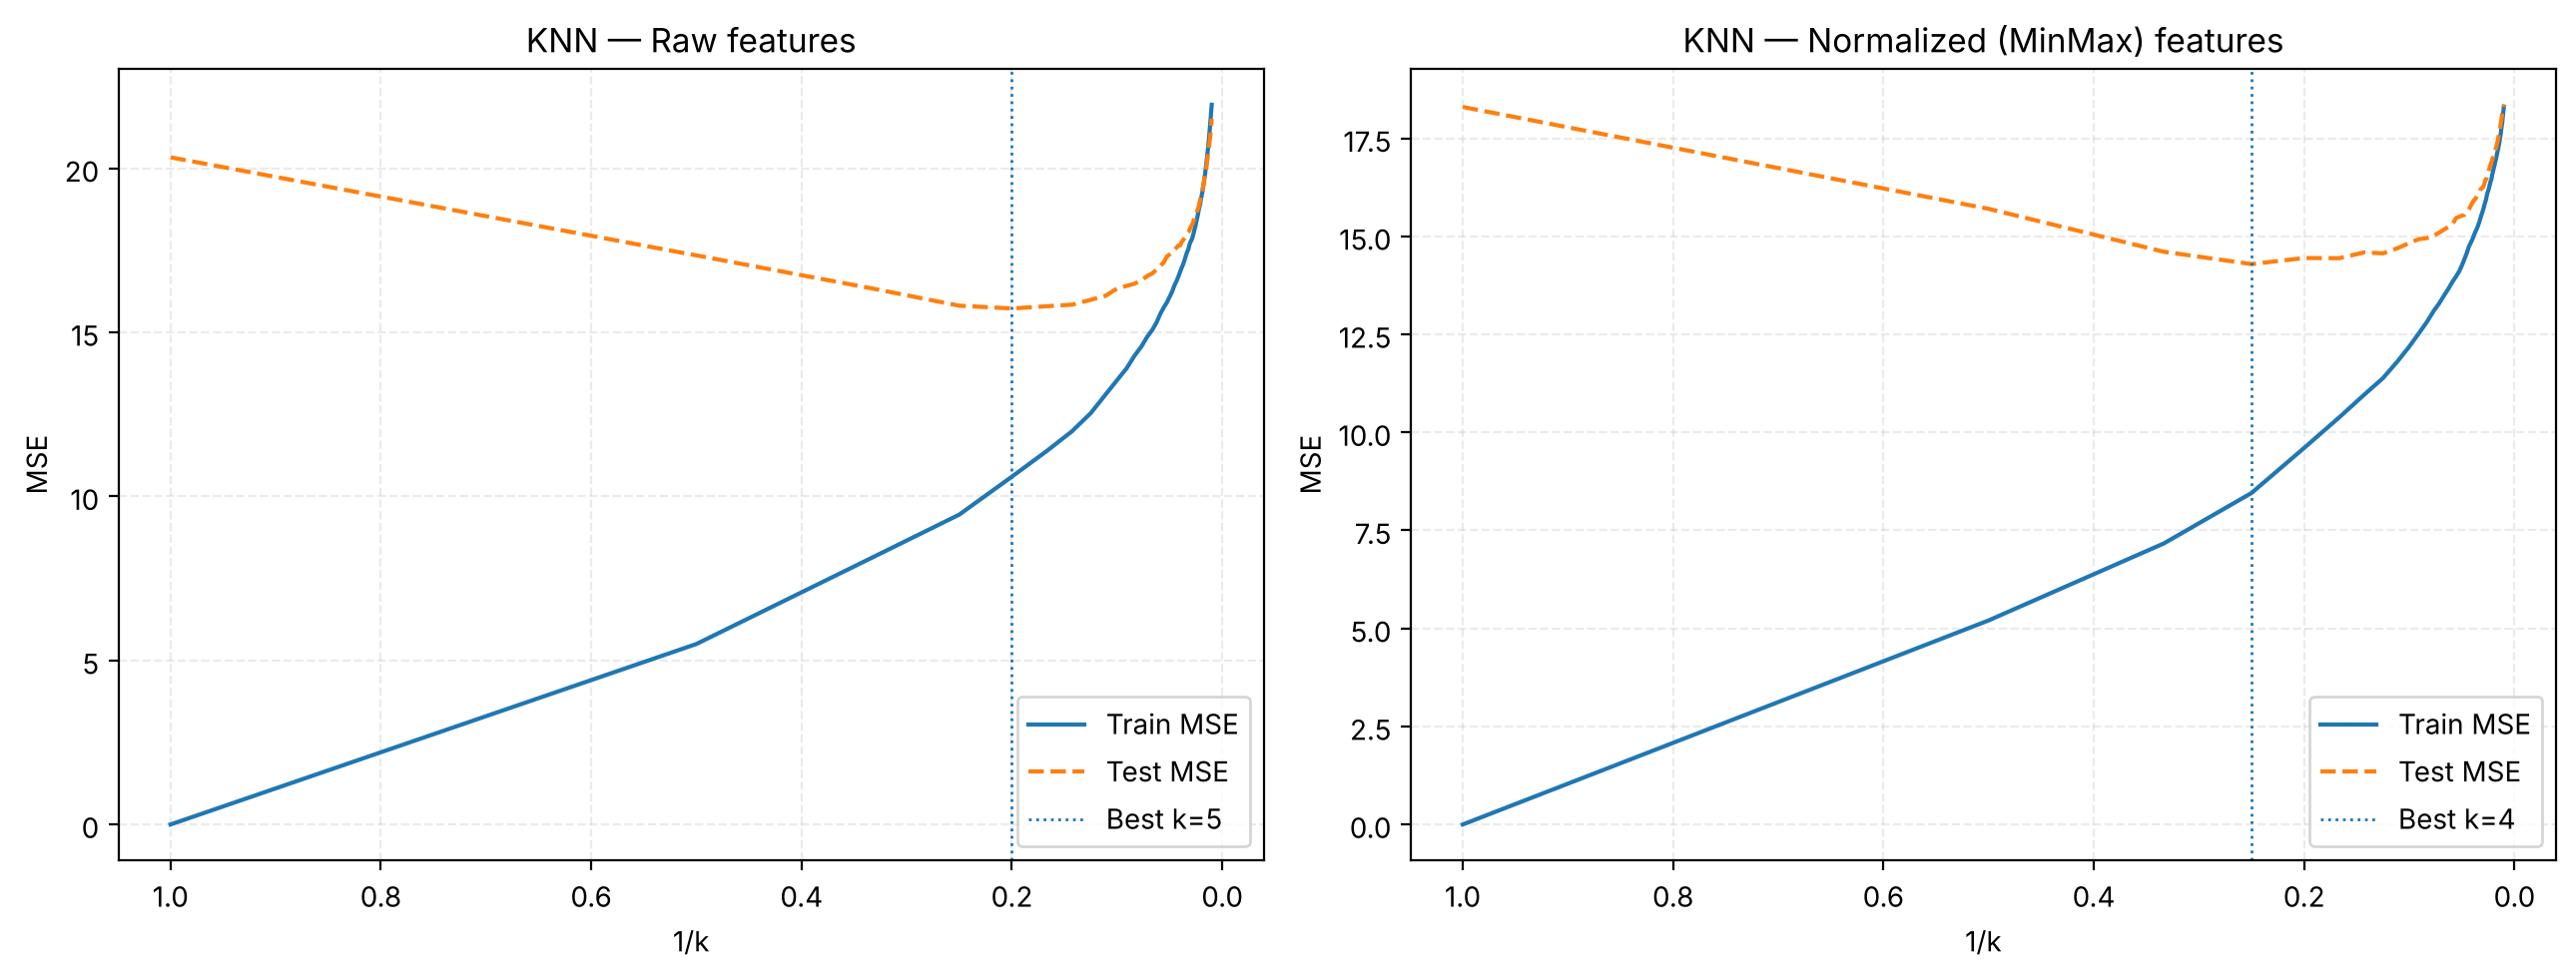

,Setting,Best k,Best test MSE
0,Raw features,5,15.726820
1,Normalized (MinMax),4,14.291333


In [25]:
best_idx_raw = int(results_knn['test_mse_raw'].idxmin())
best_k_raw   = int(results_knn.loc[best_idx_raw, 'k'])
best_test_raw = float(results_knn.loc[best_idx_raw, 'test_mse_raw'])

best_idx_norm = int(results_knn['test_mse_norm'].idxmin())
best_k_norm   = int(results_knn.loc[best_idx_norm, 'k'])
best_test_norm = float(results_knn.loc[best_idx_norm, 'test_mse_norm'])

print(f"Best k (raw features):        {best_k_raw}  -> Test MSE = {best_test_raw:.4f}")
print(f"Best k (normalized features): {best_k_norm}  -> Test MSE = {best_test_norm:.4f}")

# Plot train/test errors vs 1/k (
inv_k = 1.0 / results_knn['k'].values

fig, axes = plt.subplots(1, 2, figsize=(13,5))

# Raw features plot
ax = axes[0]
ax.plot(inv_k, results_knn['train_mse_raw'],    label='Train MSE', linestyle='-')
ax.plot(inv_k, results_knn['test_mse_raw'],     label='Test MSE',  linestyle='--')
ax.axvline(1.0/best_k_raw, linestyle=':', linewidth=1.0, label=f'Best k={best_k_raw}')
ax.invert_xaxis()
ax.set_xlabel('1/k')
ax.set_ylabel('MSE')
ax.set_title('KNN — Raw features')
ax.grid(alpha=0.25, linestyle='--')
ax.legend()

# Normalized features plot
ax = axes[1]
ax.plot(inv_k, results_knn['train_mse_norm'],   label='Train MSE', linestyle='-')
ax.plot(inv_k, results_knn['test_mse_norm'],    label='Test MSE',  linestyle='--')
ax.axvline(1.0/best_k_norm, linestyle=':', linewidth=1.0, label=f'Best k={best_k_norm}')
ax.invert_xaxis()
ax.set_xlabel('1/k')
ax.set_ylabel('MSE')
ax.set_title('KNN — Normalized (MinMax) features')
ax.grid(alpha=0.25, linestyle='--')
ax.legend()

plt.tight_layout()
plt.show()

# Show final numeric table for the best ks
display(pd.DataFrame({
    'Setting': ['Raw features', 'Normalized (MinMax)'],
    'Best k': [best_k_raw, best_k_norm],
    'Best test MSE': [best_test_raw, best_test_norm]
}))

## 8. KNN vs. linear regression


In [26]:
comparison = pd.DataFrame({
    'Model': [
        'Best linear model (interactions + squares)',
        f'KNN (Raw features, k={best_k_raw})',
        f'KNN (Normalized features, k={best_k_norm})'
    ],
    'Test MSE': [
        test_mse_enh,
        best_test_raw,
        best_test_norm
    ]
})

comparison

,Model,Test MSE
0,Best linear model (interactions + squares),18.660040
1,"KNN (Raw features, k=5)",15.726820
2,"KNN (Normalized features, k=4)",14.291333


**KNN vs. linear regression.** The best KNN model (min-max scaled, k = 4) reaches a test MSE of **14.29**, 23% below the best linear model's 18.66. Scaling matters: on raw features, ambient pressure (around 1,013 mbar) dominates the distance, and the best test MSE is 15.73.

KNN captures the curvature and interactions without being told about them. The linear model is still far more interpretable: it says *how much* each degree of temperature costs.

**Caveat:** k was chosen on the test set here, so 14.29 is optimistic. The README reports a 5 × 2 cross-validation where k is tuned inside each training fold.
